# CA4

### Group 3

Group members:

- Zaur Kambiev
- Vinicius Millan Santa Catharina
- Stig Espen Paulsberg


### Imports

In [22]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

from skrub                          import TableReport
from sklearn.preprocessing          import StandardScaler
from sklearn.decomposition          import PCA
from sklearn.discriminant_analysis  import LinearDiscriminantAnalysis as LDA
from sklearn.linear_model           import LogisticRegression
from sklearn.svm                    import SVC
from sklearn.pipeline               import make_pipeline
from sklearn.model_selection        import train_test_split
from sklearn.metrics                import classification_report
from sklearn.model_selection        import StratifiedKFold


### Reading data

In [23]:
df = pd.read_csv("dat-200-ca-4-h-2026/trainCA4DAT200.csv").drop(columns='CustomerId')

### Data exploration and visualisation

In [24]:
TableReport(df)

Processing column  20 / 20


,,,,,,,,,,,,,,,,,,,,


In [25]:
df.head()

,State,AccountLength,AreaCode,InternationalPlan,VoiceMailPlan,NumVoiceMailMessages,DayMinutes,DayCalls,DayCharge,EveMinutes,EveCalls,EveCharge,NightMinutes,NightCalls,NightCharge,IntlMinutes,IntlCalls,IntlCharge,CustomerServiceCalls,Churn
0,NJ,87,510,no,no,0,223.2,109,37.94,127.5,86,10.84,289.3,83,13.02,14.5,4,3.92,3,0
1,RI,114,510,no,yes,28,225.8,94,38.39,193.0,117,16.41,232.4,100,10.46,8.4,9,2.27,4,0
2,ND,55,415,no,no,0,180.1,77,30.62,235.5,98,20.02,169.4,104,7.62,11.1,2,3.00,0,0
3,DC,100,510,yes,no,0,68.5,110,11.65,337.1,115,28.65,205.2,99,9.23,12.1,9,3.27,0,0
4,AL,74,408,no,yes,46,277.7,109,47.21,270.0,114,22.95,165.3,82,7.44,10.4,2,2.81,1,0


In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   State                 3500 non-null   str    
 1   AccountLength         3500 non-null   int64  
 2   AreaCode              3500 non-null   int64  
 3   InternationalPlan     3500 non-null   str    
 4   VoiceMailPlan         3500 non-null   str    
 5   NumVoiceMailMessages  3500 non-null   int64  
 6   DayMinutes            3500 non-null   float64
 7   DayCalls              3500 non-null   int64  
 8   DayCharge             3500 non-null   float64
 9   EveMinutes            3500 non-null   float64
 10  EveCalls              3500 non-null   int64  
 11  EveCharge             3500 non-null   float64
 12  NightMinutes          3500 non-null   float64
 13  NightCalls            3500 non-null   int64  
 14  NightCharge           3500 non-null   float64
 15  IntlMinutes           3500 non-n

In [27]:
df['AreaCode'].nunique()

3

In [28]:
numerical_features = [
    'AccountLength',
    'NumVoiceMailMessages',
    'DayMinutes',
    'DayCalls',
    'DayCharge',
    'EveMinutes',
    'EveCalls',
    'EveCharge',
    'NightMinutes',
    'NightCalls',
    'NightCharge',
    'IntlMinutes',
    'IntlCalls',
    'IntlCharge',
    'CustomerServiceCalls'
]

categorical_features = [
    'State',
    'AreaCode',
    'InternationalPlan',
    'VoiceMailPlan',
    'Churn'
]

In [29]:
print(df[numerical_features].info())

<class 'pandas.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   AccountLength         3500 non-null   int64  
 1   NumVoiceMailMessages  3500 non-null   int64  
 2   DayMinutes            3500 non-null   float64
 3   DayCalls              3500 non-null   int64  
 4   DayCharge             3500 non-null   float64
 5   EveMinutes            3500 non-null   float64
 6   EveCalls              3500 non-null   int64  
 7   EveCharge             3500 non-null   float64
 8   NightMinutes          3500 non-null   float64
 9   NightCalls            3500 non-null   int64  
 10  NightCharge           3500 non-null   float64
 11  IntlMinutes           3500 non-null   float64
 12  IntlCalls             3500 non-null   int64  
 13  IntlCharge            3500 non-null   float64
 14  CustomerServiceCalls  3500 non-null   int64  
dtypes: float64(8), int64(7)
memory u

Check for missing values

In [30]:
print(df.isna().sum())

State                   0
AccountLength           0
AreaCode                0
InternationalPlan       0
VoiceMailPlan           0
NumVoiceMailMessages    0
DayMinutes              0
DayCalls                0
DayCharge               0
EveMinutes              0
EveCalls                0
EveCharge               0
NightMinutes            0
NightCalls              0
NightCharge             0
IntlMinutes             0
IntlCalls               0
IntlCharge              0
CustomerServiceCalls    0
Churn                   0
dtype: int64


Check for duplicated values

In [31]:
df.duplicated().sum()

np.int64(0)

In [32]:
# sns.pairplot(
#     data=df.drop(columns=['State', 'AreaCode', 'InternationalPlan', 'VoiceMailPlan']),
#     hue='Churn'
# )

#### Box plots

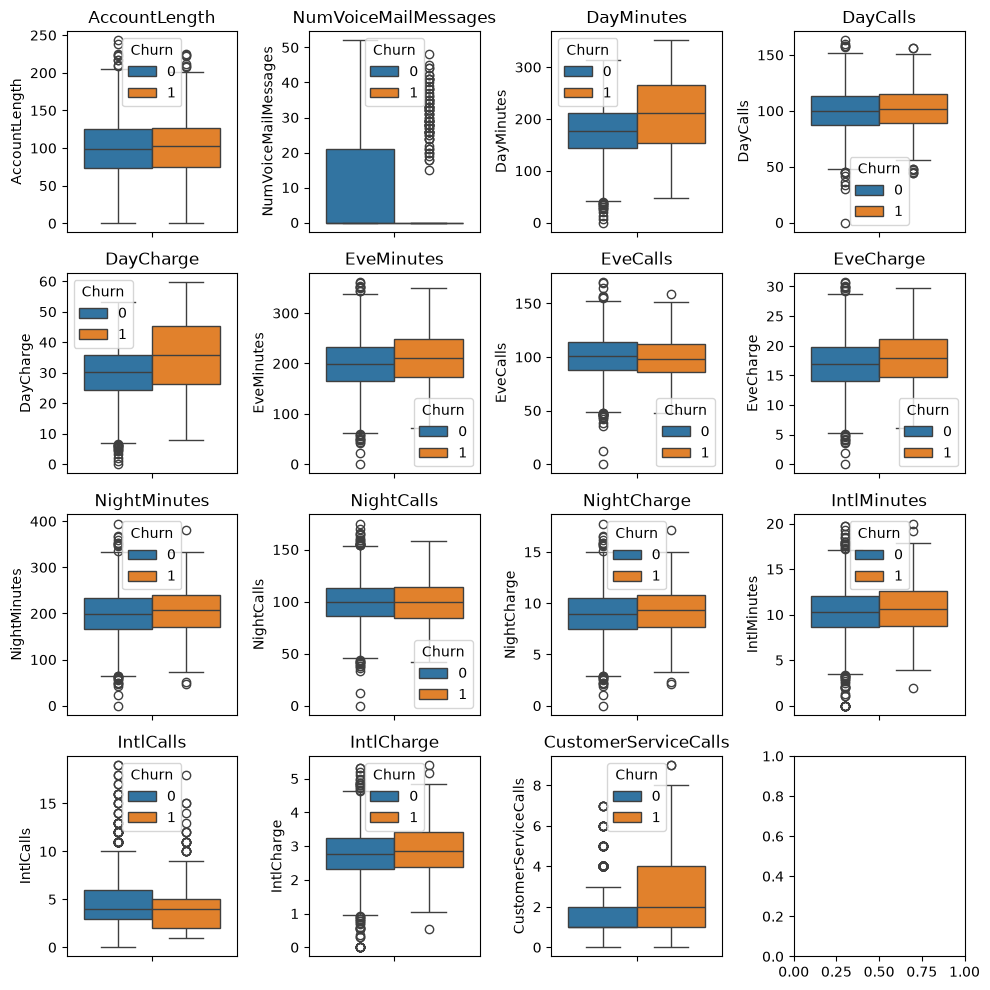

In [33]:
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
axes = axes.ravel()

for i, feature in enumerate(numerical_features):
    sns.boxplot(
        data=df,
        y=feature,
        ax=axes[i],
        hue='Churn'
    )
    axes[i].set_title(feature)
    
plt.tight_layout()
plt.show()

#### Heatmap

Must clean data before visualising

#### Outliers

Not sure if we should keep it. Outliers might be the most important part for this dataset actually. Need to discuss further.

In [34]:
# for feature in numerical_features:
#     # z threshold
#     z_threshold = 3
    
#     # Create figure with 2 subplots for each feature
#     fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    
#     # Plot before outliers removal
#     axes[0].hist(
#         df[feature],
#         bins=30,
#         alpha=0.7,
#         color='blue'
#     )
#     axes[0].set_title(f'{feature} - Before removal of outliers')
#     axes[0].set_xlabel(feature)
#     axes[0].set_ylabel('Frequency')
    
#     # Z-score
#     z_score = (df[feature] - np.mean(df[feature])) / (np.std(df[feature] + 1e-10))
    
#     # Plot after outlier removal
#     df_clean = df[np.abs(z_score) <= z_threshold]
#     axes[1].hist(
#         df_clean[feature],
#         bins=30,
#         alpha=0.7,
#         color='green'
#     )
#     axes[1].set_title(f'{feature} - After removal of outliers')
#     axes[1].set_xlabel(feature)
#     axes[1].set_ylabel('Frequency')
    
#     plt.tight_layout()
#     plt.show()
#     # plt.savefig(f"{feature}.png")
#     plt.close(fig)
    

#### Summary

Numerical features looks ok regarding correct datatype. Categorical features needs some processing. We need to change from yes/no to 1/0.
There are no missing values, and no duplicated values.
*AreaCode* has 3 unique values, so it might be useful to one hot encode this feature.
Need to check for outliers as well.

Haven't decided if cleaning up regarding outliers is a good idea.

### Data cleaning

One hot encoding

In [35]:
# One-hot-encode column AreaCode
df = pd.get_dummies(
    df,
    columns=['AreaCode'],
    drop_first=True # Dropping first to avoid colinearity
)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   State                 3500 non-null   str    
 1   AccountLength         3500 non-null   int64  
 2   InternationalPlan     3500 non-null   str    
 3   VoiceMailPlan         3500 non-null   str    
 4   NumVoiceMailMessages  3500 non-null   int64  
 5   DayMinutes            3500 non-null   float64
 6   DayCalls              3500 non-null   int64  
 7   DayCharge             3500 non-null   float64
 8   EveMinutes            3500 non-null   float64
 9   EveCalls              3500 non-null   int64  
 10  EveCharge             3500 non-null   float64
 11  NightMinutes          3500 non-null   float64
 12  NightCalls            3500 non-null   int64  
 13  NightCharge           3500 non-null   float64
 14  IntlMinutes           3500 non-null   float64
 15  IntlCalls             3500 non-n

Correct categories for features

In [36]:
# Change category values yes/no to 1/0. 
df[['InternationalPlan', 'VoiceMailPlan']] = df[['InternationalPlan', 'VoiceMailPlan']].replace({
    'yes': 1,
    'no': 0,
})

df = df.astype(
    {
        'State': 'category',
        'InternationalPlan': 'bool',
        'VoiceMailPlan': 'bool',
        'Churn': 'bool'
    }
)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3500 entries, 0 to 3499
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   State                 3500 non-null   category
 1   AccountLength         3500 non-null   int64   
 2   InternationalPlan     3500 non-null   bool    
 3   VoiceMailPlan         3500 non-null   bool    
 4   NumVoiceMailMessages  3500 non-null   int64   
 5   DayMinutes            3500 non-null   float64 
 6   DayCalls              3500 non-null   int64   
 7   DayCharge             3500 non-null   float64 
 8   EveMinutes            3500 non-null   float64 
 9   EveCalls              3500 non-null   int64   
 10  EveCharge             3500 non-null   float64 
 11  NightMinutes          3500 non-null   float64 
 12  NightCalls            3500 non-null   int64   
 13  NightCharge           3500 non-null   float64 
 14  IntlMinutes           3500 non-null   float64 
 15  IntlCalls      

### Data exploration & visualisation after cleaning

##### Heatmap

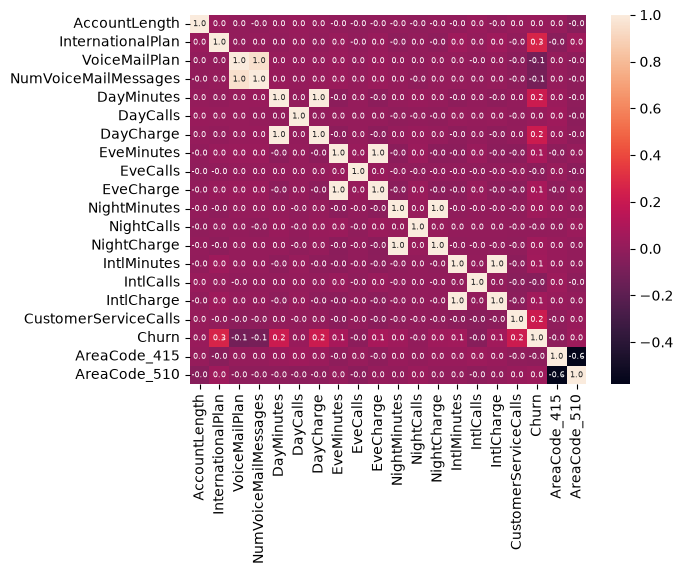

In [37]:
sns.heatmap(
    df.drop(columns='State').corr(),
    annot=True,
    fmt='.1f',
    annot_kws={
        'size': 6
    }
)
plt.show()

Smaller heatmap

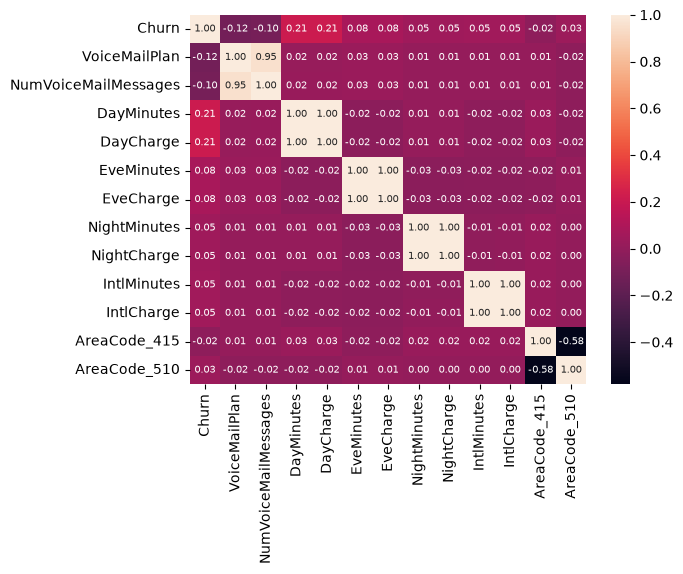

In [38]:
selected_features = [
    'Churn',
    'VoiceMailPlan',
    'NumVoiceMailMessages',
    'DayMinutes',
    'DayCharge',
    'EveMinutes',
    'EveCharge',
    'NightMinutes',
    'NightCharge',
    'IntlMinutes',
    'IntlCharge',
    'AreaCode_415',
    'AreaCode_510'
]

sns.heatmap(
    df[selected_features].corr(),
    annot=True,
    fmt=".2f",
    annot_kws={
        'size': 7,
    }
)
plt.show()

##### Summary

We can remove the feature regarding minutes for Day, Eve, Night, and Intl.

Regarding *VoiceMailPlan* and *NumVoiceMailMessages*, maybe *NumVoiceMailMessages* because it is easier to interpret a yes or no feature than a continuous one (?). Might depend on the choice of model?

Or are both of these features important to understand churn?

### Preprocessing

In [39]:
features = [
    'AccountLength',
    'VoiceMailPlan',
    'NumVoiceMailMessages',
    'DayCalls',
    'DayCharge',
    'EveCalls',
    'EveCharge',
    'NightCalls',
    'NightCharge',
    'IntlCalls',
    'IntlCharge',
    'CustomerServiceCalls',
    'AreaCode_415',
    'AreaCode_510',
    # 'State',
    'InternationalPlan'
]

target = [
    'Churn'
]

X = df[features]
y = df[target]

In [40]:
X_train, X_val, y_train, y_val= train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

### Pipeline

In [ ]:
c_param = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
gamma_param = 

pipeline_svd = make_pipeline(
    StandardScaler(),
    LDA(n_components=None),
    SVC(
        random_state=42,
        kernel='rbf'
    )
)
pipeline_svd

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('lineardiscriminantanalysis', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide <array_api>` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`tr

In [50]:
# Train the pipeline
pipeline_svd.fit(X_train, y_train)

# Predict
y_pred = pipeline_svd.predict(X_val)

print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

       False       0.86      1.00      0.92       601
        True       0.00      0.00      0.00        99

    accuracy                           0.86       700
   macro avg       0.43      0.50      0.46       700
weighted avg       0.74      0.86      0.79       700



/home/stig-espen-paulsberg/Documents/Utdanning/DAT200/dat200-ca4/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/stig-espen-paulsberg/Documents/Utdanning/DAT200/dat200-ca4/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/stig-espen-paulsberg/Documents/Utdanning/DAT200/dat200-ca4/.venv/lib/python3.14/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitaliz

In [43]:
pipeline_logreg = make_pipeline(
    StandardScaler(),
    LDA(n_components=None),
    LogisticRegression(
        random_state=42,
        max_iter=250
    )
)
pipeline_logreg

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('lineardiscriminantanalysis', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide <array_api>` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`tr

In [44]:
# Train the pipeline
pipeline_logreg.fit(X_train, y_train)

# Predict
y_pred = pipeline_logreg.predict(X_val)

print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

       False       0.87      0.96      0.91       601
        True       0.37      0.15      0.21        99

    accuracy                           0.84       700
   macro avg       0.62      0.55      0.56       700
weighted avg       0.80      0.84      0.81       700



/home/stig-espen-paulsberg/Documents/Utdanning/DAT200/dat200-ca4/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/stig-espen-paulsberg/Documents/Utdanning/DAT200/dat200-ca4/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


### Model

### Evaluating models/hyperparameters (cross-validation)

### Kaggle submission